## DABN13 - Assignment 3
In line with Lecture 7, Assignment 3 is somewhat more technical. This means there are no basic warm-up tasks since even the use of a canned routine for optimization requires us to write a function for our cost function.

Still, this assignment covers frequently occurring coding tasks in the context of function optimization. That is, you will write many functions, transfer a lot of mathematical expressions from the lecture slides into this script, create some simple plots and, most importantly, spend far too much time on trying to figure out what is wrong with your code. On the upside, this assignment gives you a little more freedom to write code in your own way. Enjoy!

### Preamble: Preparing the data

We are going to recycle a dataset on purchases in online shops that we already used in Assignment 1. 
Load the data into python and save it in an object called `shoppers`. The dataset is contained in a comma-separated spreadsheet. Accordingly, you will need to use the `read_csv()` command in python.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

shoppers = pd.read_csv("../1.data/online_shoppers_intention.csv") #Adjust file path

In the steps below, we will fit a quite small logistic regression model including the following variables in addition to the intercept:

1. ` ExitRates ` without further transformation
2. The (natural) logarithm of ` ProductRelated_Duration + 1 `

The code below does all data transformations for you. However, please note the shortened variable names that we are going to use from now on.

In [2]:
shoppers = shoppers.rename(columns={"ExitRates": "ER"})
shoppers["lPR_Dur"] = np.log(shoppers["ProductRelated_Duration"] +1)
shoppers["constant"] = 1
X        = np.asarray(shoppers[["constant", "ER", "lPR_Dur"]])

y        = np.ones((X.shape[0],1))
y[shoppers["Revenue"]==False] = -1

## Part 1: Learning logistic regression without `sklearn`

### Task 1a)

If we want to learn a logistic regression manually, we need to specify the cost function that we are going to minimize. So as a first step, create a function `cost_logistic_1a()` whose inputs are 

1. `theta`: a one-dimensional NumPy array of coefficients,
2. `y`: a $n \times 1$ NumPy array of outputs,
3. `X`: a $n \times p$ NumPy array of inputs.

The function is then supposed to return the cost on the data consisting of `y` and `X` with logistic loss and coefficient vector values `theta`.


In [3]:
# CODE_CHUNK code_chunk_01
def cost_logistic_1a(theta, y, X):
    # logistic loss log(1 + exp(-y * x'theta)), averaged over observations
    # np.logaddexp(0, m) = log(1 + exp(m)) without overflow for large m
    margin = y.ravel() * (X @ theta)
    return np.mean(np.logaddexp(0, -margin))

### Task 1b)

As a next step, we need a function that returns the gradient of the cost function. Write such a function `grad_logistic_1b()` that takes the same arguments as `cost_logistic_1a()` and which returns a one-dimensional NumPy array (with $p$ elements) containing the gradient of our cost function.

In [4]:
# CODE_CHUNK code_chunk_02
def grad_logistic_1b(theta, y, X):
    # d/dtheta log(1 + exp(-m)) = -y x * sigmoid(-m), with m = y * x'theta
    margin = y.ravel() * (X @ theta)
    weights = -y.ravel() * np.exp(-np.logaddexp(0, margin))   # sigmoid(-m) = 1/(1+exp(m))
    return X.T @ weights / X.shape[0]

### Task 1c)

A canned routine for optimization is provided in the SciPy package: The `minimize()` function. `minimize()` minimizes a function that you feed into it. It also allows you to provide a gradient function to speed up optimization and to achieve better numerical stability in complicated cases. 

The function minimized by `minimize()` should have only one argument: The parameters of our minimization problem. This does not really fit the structure of `cost_logistic_1a` and `grad_logistic_1b` which have three arguments each. However, the last two arguments specify the data that we use. Therefore we make a short detour to arrive at functions of one argument only.

1. Create a [lambda function](https://docs.python.org/3/reference/expressions.html#lambdas) `cost_logistic_1c` which takes `theta` as its only input and which calls `cost_logistic_1a` from Task 1a with `theta` as well as  the previously created output `y` and inputs `X`.
2. In the same fashion, create a lambda function `grad_logistic_1c` that turns `grad_logistic_1b` into a function with one single argument `theta` as well as `y` and `X` as (fixed) output and inputs, respectively.



In [5]:
# CODE_CHUNK code_chunk_03
cost_logistic_1c = lambda theta: cost_logistic_1a(theta, y, X)
grad_logistic_1c = lambda theta: grad_logistic_1b(theta, y, X)

### Task 1d) 
The`minimize()`-function allows you to choose from several algorithms from the very broad literature on optimization methods. We are going to use the `BFGS` method which is a very popular modification of Newton's method. 

Now use `minimize()` to minimize `cost_logistic_1c` on your training data. Follow the instructions below:

1. Let all initial coefficient values be zero.
2. Choose the BFGS minimization method.
3. Supply your gradient function `grad_logistic_1c` as well. If you could not solve Task 1b, leave out the gradient. 
4. Use the desired tolerance level `tol_1d` as the tolerance argument.

Save the resulting list object as `optim_result_1d`.

In [6]:
# CODE_CHUNK code_chunk_04
from scipy.optimize import minimize

tol_1d = 1e-9

optim_result_1d  = minimize(cost_logistic_1c, x0=np.zeros(X.shape[1]), jac=grad_logistic_1c,
                            method="BFGS", tol=tol_1d)

print(optim_result_1d)

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 0.38688976841366607
        x: [-2.489e+00 -3.028e+01  2.474e-01]
      nit: 36
      jac: [ 3.473e-11  3.441e-13  2.297e-10]
 hess_inv: [[ 3.440e+02 -1.397e+03 -4.490e+01]
            [-1.397e+03  3.550e+04  9.731e+01]
            [-4.490e+01  9.731e+01  6.273e+00]]
     nfev: 38
     njev: 38


### Task 1e) 

Have a closer look at the OptimizeResult object `optim_result_1d`. What do its different components tell us about our solved minimization problem? Explain this in your *own* words by writing explanations into the four string variables below.

In [7]:
# CODE_CHUNK code_chunk_05
whatis_x_1d       = "x is the coefficient vector at which minimize() stopped, i.e. the estimated minimizer of the cost function: the logistic regression coefficients for the intercept, ER and lPR_Dur (about -2.49, -30.28 and 0.25)."
whatis_fun_1d     = "fun is the value of the cost function (average logistic loss) at x, i.e. the smallest cost that the algorithm found (about 0.3869). It is the benchmark that we compare gradient descent and Newton's method against."
whatis_nit_1d     = "nit is the number of iterations (BFGS updates of the coefficients) that were needed until the stopping criterion was met. Here it is only 36, far fewer than the 5000 updates that we allow for gradient descent."
whatis_success_1d = "success is a Boolean flag that tells whether the optimizer terminated successfully, i.e. whether it met its convergence criterion (gradient norm below the tolerance) instead of stopping because of an error or a limit on the number of iterations. Here it is True, so we can trust x to be a (numerical) minimum."

## Part 2: Gradient descent manually

In this part, you are going to write your own routine for gradient descent.

**(12 points)**

Below, I have prepared a fragment of a function that is supposed to conduct gradient descent. This function, `grad_desc`, takes the following inputs:

- `par`: initial coefficient values as one-dimensional NumPy array
- `fn`: The objective function
- `gr`: The gradient of the objective function
- `stepsize`: The step size 
- `maxitr`: The maximum number of parameter updates. Default is set to 5000.
- `tol`: The tolerance for coefficient updates to be considered "effectively 0". Default is set to 0.000001
-  `y`: an $n \times 1$ NumPy array of outputs
-  `X`: an $n \times p$ NumPy array of inputs.

Additionally, the function already contains the following objects:

- `coef_path`: A two-dimensional NumPy array whose columns eventually contain the entire sequence of coefficient vectors,
- `coef_upd`: A two-dimensional NumPy array whose columns eventually contain the entire sequence of coefficient updates,
- `fn_path`: A one-dimensional NumPy array that eventually contains all values of the objective function.

Your task is to write code that conducts the coefficient updates of gradient descent until the Euclidean norm of a coefficient update is below the tolerance level `tol`. 

The full sequence of coefficient vectors, coefficient updates and function values should be saved in the objects `coef_path`, `coef_upd` and `fn_path`, respectively. Maximally `maxitr` coefficient updates should be made (fewer if coefficient updates are below tolerance).

In [8]:
# CODE_CHUNK code_chunk_06
def grad_desc(par, fn, gr, stepsize, maxitr=5000, tol=1e-6, y=None, X=None):

    # Don't change anything here
    coef_path = par[:,None]
    coef_upd  = np.empty((len(par), 0))
    fn_path   = [fn(theta=par, X=X, y=y)]
    
    # Start writing stuff here
    itr = 0
    while itr < maxitr:
        theta  = coef_path[:,-1]
        update = -stepsize * gr(theta=theta, X=X, y=y)
        if np.linalg.norm(update) < tol:
            break
        theta_new = theta + update
        coef_path = np.column_stack((coef_path, theta_new))
        coef_upd  = np.column_stack((coef_upd, update))
        fn_path.append(fn(theta=theta_new, X=X, y=y))
        itr += 1
    fn_path = np.array(fn_path)
    
    # Don't change anything here
    return {
        'coef_final': coef_path[:,-1],
        'itr': itr,
        'coef_path': coef_path,
        'updates': coef_upd,
        'fun_path': fn_path
    }

### Task 2b) 

Now we tune the step size of gradient descent. In order to do this, write a function `plot_cost_2b` which runs gradient descent with a chosen step size and only 100 coefficient updates. The function should then create an object containing a line plot of the number of coefficient updates against the cost at the specific update. 

I have already prepared a dictionary object `gd_ctrl_2b` for you that contains the gradient descent function as well as most inputs to this function. Use `gd_ctrl_2b` as an input and define further arguments to your step size as well as the data.

Once you have created `plot_cost_2b`, play around with different step sizes. Save a plot with a step size that you deem as too low (high) as object `plot_tooLO_2b` (`plot_tooHI_2b`). Save another plot `plot_decent_2b` which contains the development of cost with a good step size.

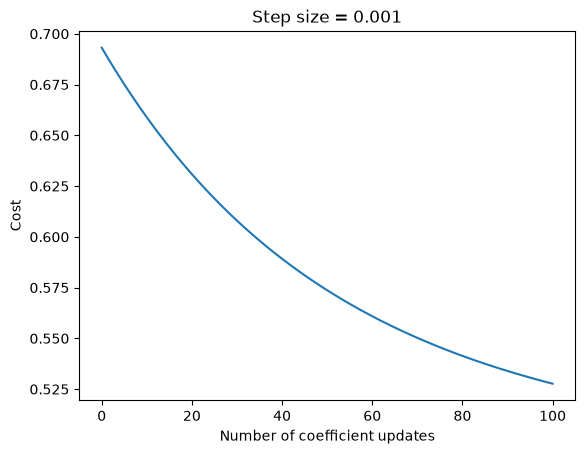

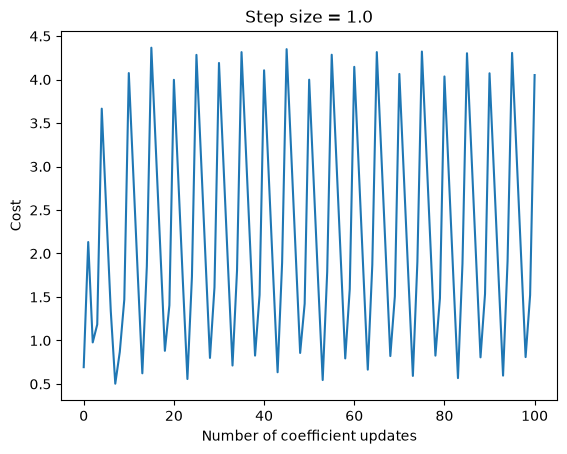

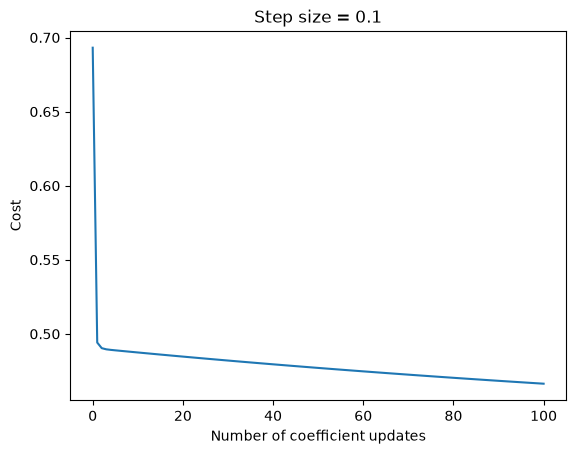

In [9]:
# CODE_CHUNK code_chunk_07
gd_ctrl_2b = {
    'par': np.array([0, 0, 0]),
    'fn': cost_logistic_1a,
    'gr': grad_logistic_1b,
    'gd_fun': grad_desc,
    'maxitr': 100
}

def plot_cost_2b(ctrl, stepsize, y, X):
    res = ctrl['gd_fun'](par=ctrl['par'], fn=ctrl['fn'], gr=ctrl['gr'], stepsize=stepsize,
                         maxitr=ctrl['maxitr'], y=y, X=X)
    fig, ax = plt.subplots()
    ax.plot(np.arange(len(res['fun_path'])), res['fun_path'])
    ax.set_xlabel("Number of coefficient updates")
    ax.set_ylabel("Cost")
    ax.set_title(f"Step size = {stepsize}")
    plt.close(fig)   # show a figure only when we ask for it
    return fig

# Step size too low:
plot_tooLO_2b = plot_cost_2b(gd_ctrl_2b, 1e-3, y, X)
# Step size too high:
plot_tooHI_2b = plot_cost_2b(gd_ctrl_2b, 1.0, y, X)
# Step size quite ok:
plot_decent_2b = plot_cost_2b(gd_ctrl_2b, 0.1, y, X)

for p in (plot_tooLO_2b, plot_tooHI_2b, plot_decent_2b):
    display(p)

### Task 2c) 

Use the string variable `stepsize_motivate_2c` to motivate why you chose the three step size examples in Task 2b. More specifically, explain what lead you to the conclusion that a step size is too low or too high.

In [10]:
# CODE_CHUNK code_chunk_08
stepsize_motivate_2c = "I plotted the cost against the number of updates for several step sizes. Step size 0.001 is too low: the cost falls smoothly but extremely slowly (from 0.693 to only about 0.53 after 100 updates, far from the minimum of 0.387), so we would waste a huge number of updates. Step size 1.0 is too high: each update overshoots the minimum, so the cost jumps up in the first update (0.693 to 2.13) and then oscillates around 4 without ever decreasing; the algorithm diverges. Step size 0.1 is quite ok: the cost decreases in every update, drops fast at the start (0.693 to 0.49 after one update) and keeps falling afterwards without oscillating. Step sizes of 0.5 and above already lead to non-monotone cost paths, while 0.1 is the largest of the values I tried (0.001, 0.01, 0.05, 0.1, 0.2, 0.5, 1) that I trust to be stable for this problem."

### Task 2d) 

Use `grad_desc` with your chosen step size to learn the coefficients of the logistic regression model that we have been working with so far. Keep the maximum number of updates at its default value. Save the resulting object as `gd_result_2d`. 

Does gradient descent stop before the maximum number of updates? If not, how far does gradient descent get the cost function towards the value achieved by `minimize()` in Task 1c? Write your answer into the string variable `gd_conclusion_2d`.

In [11]:
# CODE_CHUNK code_chunk_09
gd_result_2d = grad_desc(par=np.zeros(3), fn=cost_logistic_1a, gr=grad_logistic_1b,
                         stepsize=0.1, y=y, X=X)
print(gd_result_2d['itr'], gd_result_2d['coef_final'], gd_result_2d['fun_path'][-1])
print(optim_result_1d.fun, optim_result_1d.x)

gd_conclusion_2d = "No, gradient descent does not stop early: it uses all 5000 updates, because the norm of the last update (about 1.7e-4) is still above the tolerance 1e-6. Its final cost is about 0.4032, compared with 0.3869 from minimize(), so it closes most of the gap from the starting cost of 0.693 but is still about 0.016 above the minimum. The coefficients are also still far away from the minimize() solution (ER is about -1.19 instead of -30.28), because the cost is very flat in the direction of ER and a larger step size is not possible without diverging along the steep directions. Gradient descent is still making slow progress, so many more updates would be needed."

5000 [-4.05301864 -1.18766853  0.37442093] 0.40324885333236576
0.38688976841366607 [ -2.48931966 -30.28156663   0.24744927]


## Part 3: Newton's method manually

Given that you have implemented gradient descent in Part 2, you have already done most of the hard work that is required for Newton's method. After all, the only thing that differs is the expression for your coefficient update. For this reason, we will work on our own routine for Newton's method.

### Task 3a) 
Newton's method is more demanding than gradient descent in that it requires us to obtain the Hessian of our objective function for any desired vector of coefficients. Write such as function `hessian_logistic_3a` which has the same arguments as `grad_logistic_1b` and which returns the hessian of your cost function with logistic loss.

In [12]:
# CODE_CHUNK code_chunk_10
def hessian_logistic_3a(theta, y, X):
    # H = 1/n * X' diag(p (1 - p)) X with p = sigmoid(x'theta); does not depend on y
    p = 1 / (1 + np.exp(-(X @ theta)))
    return (X * (p * (1 - p))[:, None]).T @ X / X.shape[0]

### Task 3b) 

Modify `grad_desc` to turn it into a function for Newton's method. This only requires you to remove step size from the function arguments, to add a new argument for the Hessian and to change the line for your coefficient update. Save your function as object `newton_3b`.

In [13]:
# CODE_CHUNK code_chunk_11
def newton_3b(par, fn, gr, hess, maxitr=5000, tol=1e-6, y=None, X=None):

    coef_path = par[:,None]
    coef_upd  = np.empty((len(par), 0))
    fn_path   = [fn(theta=par, X=X, y=y)]

    itr = 0
    while itr < maxitr:
        theta  = coef_path[:,-1]
        update = -np.linalg.solve(hess(theta=theta, X=X, y=y), gr(theta=theta, X=X, y=y))
        if np.linalg.norm(update) < tol:
            break
        theta_new = theta + update
        coef_path = np.column_stack((coef_path, theta_new))
        coef_upd  = np.column_stack((coef_upd, update))
        fn_path.append(fn(theta=theta_new, X=X, y=y))
        itr += 1
    fn_path = np.array(fn_path)

    return {
        'coef_final': coef_path[:,-1],
        'itr': itr,
        'coef_path': coef_path,
        'updates': coef_upd,
        'fun_path': fn_path
    }

### Task 3c) 

Use your function `newton_3b` to learn the logistic regression model that you already learned in Tasks 1c and 2d. Keep the maximum number of updates at its default value. Save the resulting object as `nm_result_3c`. 

Does Newton's method stop before the maximum number of updates? If not, how far does Newton's method get the cost function towards the value achieved by `minimize()` in Task 1c? What is your verdict about the performance of Newton's method relative to gradient descent and the `minimize()` command in the case of logistic regression? Write your answer into the string variable `nm_conclusion_3c`.

In [14]:
# CODE_CHUNK code_chunk_12
nm_result_3c = newton_3b(par=np.zeros(3), fn=cost_logistic_1a, gr=grad_logistic_1b,
                         hess=hessian_logistic_3a, y=y, X=X)
print(nm_result_3c)
nm_conclusion_3c = "Yes, Newton's method stops before the maximum number of updates: it needs only 7 updates until the norm of the update is below the tolerance. Its final cost and coefficients agree with the result of minimize() (cost about 0.3869, coefficients about -2.49, -30.28 and 0.25), so it gets all the way to the minimum. Relative to gradient descent, which uses 5000 updates and is still about 0.016 above the minimum, Newton's method is far better in terms of the number of updates: the Hessian rescales the badly scaled directions (ER versus the intercept and lPR_Dur) so that no step size has to be tuned. It is also as accurate as minimize() with BFGS, which needs 36 iterations, although BFGS does not need the Hessian. The price is that each Newton update requires computing and solving with the p x p Hessian, which is cheap with three coefficients but becomes costly with many coefficients. For a small, smooth, convex problem like this logistic regression, Newton's method is the best of the three."

{'coef_final': array([ -2.48931966, -30.28156662,   0.24744927]), 'itr': 7, 'coef_path': array([[  0.        ,  -1.63117423,  -2.18887308,  -2.41796301,
         -2.48147726,  -2.48908005,  -2.4893193 ,  -2.48931966],
       [  0.        ,  -3.87818635, -10.53039676, -20.48226788,
        -28.19994004, -30.19194083, -30.28139822, -30.28156662],
       [  0.        ,   0.06996975,   0.14623519,   0.21068194,
          0.24136522,   0.24721646,   0.24744885,   0.24744927]]), 'updates': array([[-1.63117423e+00, -5.57698857e-01, -2.29089921e-01,
        -6.35142568e-02, -7.60278787e-03, -2.39247459e-04,
        -3.62046213e-07],
       [-3.87818635e+00, -6.65221040e+00, -9.95187113e+00,
        -7.71767216e+00, -1.99200079e+00, -8.94573845e-02,
        -1.68400011e-04],
       [ 6.99697493e-02,  7.62654394e-02,  6.44467556e-02,
         3.06832773e-02,  5.85123553e-03,  2.32397194e-04,
         4.18206701e-07]]), 'fun_path': array([0.69314718, 0.42031878, 0.39748797, 0.38886997, 0.38696959

## Declaration of AI use

If you have used AI in any aspect of your work with this assignment, please indicate this in the string variable below. There is no need to specify further.

In [15]:
AI = 'yes'